In [1]:
!pip install ultralytics
!pip install kaggle
!pip install opencv-python==4.10.0.84
!pip install tensorflow
!pip install matplotlib
!pip install scikit-learn
!pip install seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 12.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.5/62.5 MB 48.9 MB/s  0:00:01
  Attempting uninstall: opencv-python
    Found existing installation: opencv-python 5.0.0.93
    Uninstalling opencv-python-5.0.0.93:
      Successfully uninstalled opencv-python-5.0.0.93


In [2]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"samruddhimulmule","key":"50992feb1206881ac00de27a9de781a6"}'}

In [3]:
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

### Downloading Dataset

In [4]:
!kaggle datasets download \
sarthakvajpayee/ai-indian-license-plate-recognition-data

Dataset URL: https://www.kaggle.com/datasets/sarthakvajpayee/ai-indian-license-plate-recognition-data
License(s): unknown
100% 1.50M/1.50M [00:00<00:00, 191MB/s]



In [5]:
!unzip ai-indian-license-plate-recognition-data.zip

Archive:  ai-indian-license-plate-recognition-data.zip
  inflating: car.jpg                 
  inflating: data/data/train/class_0/class_0_10.jpg  
  inflating: data/data/train/class_0/class_0_11.jpg  
  inflating: data/data/train/class_0/class_0_13.jpg  
  inflating: data/data/train/class_0/class_0_14.jpg  
  inflating: data/data/train/class_0/class_0_15.jpg  
  inflating: data/data/train/class_0/class_0_18.jpg  
  inflating: data/data/train/class_0/class_0_19.jpg  
  inflating: data/data/train/class_0/class_0_2.jpg  
  inflating: data/data/train/class_0/class_0_20.jpg  
  inflating: data/data/train/class_0/class_0_21.jpg  
  inflating: data/data/train/class_0/class_0_22.jpg  
  inflating: data/data/train/class_0/class_0_23.jpg  
  inflating: data/data/train/class_0/class_0_24.jpg  
  inflating: data/data/train/class_0/class_0_25.jpg  
  inflating: data/data/train/class_0/class_0_26.jpg  
  inflating: data/data/train/class_0/class_0_27.jpg  
  inflating: data/data/train/class_0/class_0

## Importing Libraries

In [6]:
import os
import cv2
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import *
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications import ResNet50

from tensorflow.keras.callbacks import EarlyStopping

## Setting Dataset Paths

In [7]:
train_dir = "/content/data/data/train"
val_dir = "/content/data/data/val"

In [8]:
print(os.listdir(train_dir)[:5])

['class_F', 'class_N', 'class_S', 'class_0', 'class_5']


## Number Plate Recognition using Haar Cascade

In [9]:
plate_cascade = cv2.CascadeClassifier(
    "/content/indian_license_plate.xml"
)

In [10]:
print(
    plate_cascade.empty()
)

False


In [11]:
def detect_plate(img):

    image = img.copy()

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2GRAY
    )

    plates = plate_cascade.detectMultiScale(
        gray,
        scaleFactor=1.2,
        minNeighbors=7
    )

    plate = None

    for (x,y,w,h) in plates:

        plate = image[y:y+h, x:x+w]

        cv2.rectangle(
            image,
            (x,y),
            (x+w,y+h),
            (0,255,0),
            3
        )

    return image, plate

In [12]:
img = cv2.imread(
    "/content/car.jpg"
)

img = cv2.cvtColor(
    img,
    cv2.COLOR_BGR2RGB
)

In [13]:
detected_img, plate = detect_plate(img)

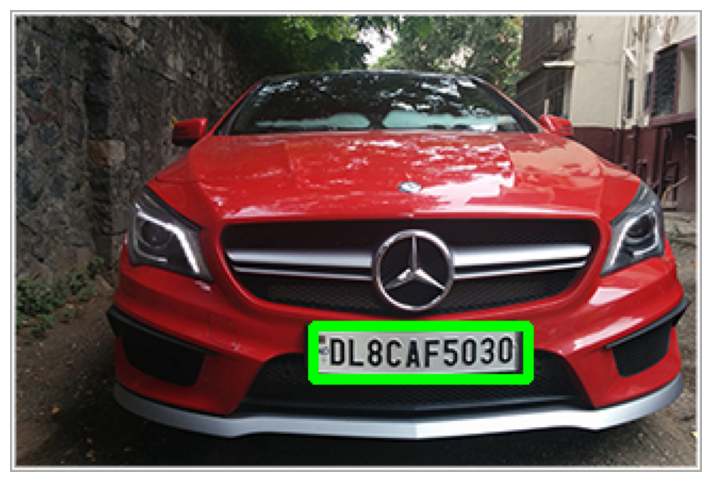

In [14]:
plt.figure(figsize=(12,6))

plt.imshow(detected_img)

plt.axis("off")

plt.show()

## Display Cropped Number Plate

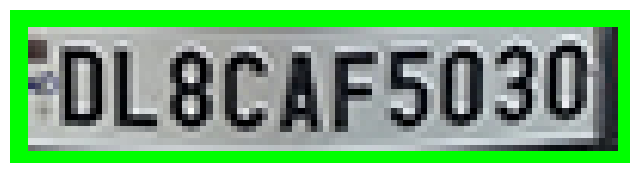

In [15]:
if plate is not None:

    plt.figure(figsize=(8,3))

    plt.imshow(plate)

    plt.axis("off")

    plt.show()

else:

    print("Plate not detected")

## Character Segmentation

In [16]:
def find_contours(dimensions, img) :

    # Find all contours in the image
    cntrs, _ = cv2.findContours(img.copy(), cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)

    # Retrieve potential dimensions
    lower_width = dimensions[0]
    upper_width = dimensions[1]
    lower_height = dimensions[2]
    upper_height = dimensions[3]

    # Check largest 5 or  15 contours for license plate or character respectively
    cntrs = sorted(cntrs, key=cv2.contourArea, reverse=True)[:15]

    ii = cv2.imread('contour.jpg')

    x_cntr_list = []
    target_contours = []
    img_res = []
    for cntr in cntrs :
        # detects contour in binary image and returns the coordinates of rectangle enclosing it
        intX, intY, intWidth, intHeight = cv2.boundingRect(cntr)

        # checking the dimensions of the contour to filter out the characters by contour's size
        if intWidth > lower_width and intWidth < upper_width and intHeight > lower_height and intHeight < upper_height :
            x_cntr_list.append(intX) #stores the x coordinate of the character's contour, to used later for indexing the contours

            char_copy = np.zeros((44,24))
            # extracting each character using the enclosing rectangle's coordinates.
            char = img[intY:intY+intHeight, intX:intX+intWidth]
            char = cv2.resize(char, (20, 40))

            cv2.rectangle(ii, (intX,intY), (intWidth+intX, intY+intHeight), (50,21,200), 2)
            plt.imshow(ii, cmap='gray')

            # Make result formatted for classification: invert colors
            char = cv2.subtract(255, char)

            # Resize the image to 24x44 with black border
            char_copy[2:42, 2:22] = char
            char_copy[0:2, :] = 0
            char_copy[:, 0:2] = 0
            char_copy[42:44, :] = 0
            char_copy[:, 22:24] = 0

            img_res.append(char_copy) # List that stores the character's binary image (unsorted)

    # Return characters on ascending order with respect to the x-coordinate (most-left character first)

    plt.show()
    # arbitrary function that stores sorted list of character indeces
    indices = sorted(range(len(x_cntr_list)), key=lambda k: x_cntr_list[k])
    img_res_copy = []
    for idx in indices:
        img_res_copy.append(img_res[idx])# stores character images according to their index
    img_res = np.array(img_res_copy)

    return img_res

In [116]:
# Find characters in the resulting images
def segment_characters(image) :

    # Preprocess cropped license plate image
    img_lp = cv2.resize(image, (333, 75))
    img_gray_lp = cv2.cvtColor(img_lp, cv2.COLOR_BGR2GRAY)
    _, img_binary_lp = cv2.threshold(img_gray_lp, 200, 255, cv2.THRESH_BINARY+cv2.THRESH_OTSU)
    img_binary_lp = cv2.erode(img_binary_lp, (3,3))
    img_binary_lp = cv2.dilate(img_binary_lp, (3,3))

    LP_WIDTH = img_binary_lp.shape[0]
    LP_HEIGHT = img_binary_lp.shape[1]

    # Make borders white
    img_binary_lp[0:3,:] = 255
    img_binary_lp[:,0:3] = 255
    img_binary_lp[72:75,:] = 255
    img_binary_lp[:,330:333] = 255

    # Estimations of character contours sizes of cropped license plates
    dimensions = [LP_WIDTH/6,
                       LP_WIDTH/2,
                       LP_HEIGHT/10,
                       2*LP_HEIGHT/3]
    plt.imshow(img_binary_lp, cmap='gray')
    plt.show()
    cv2.imwrite('contour.jpg',img_binary_lp)

    # Get contours within cropped license plate
    char_list = find_contours(dimensions, img_binary_lp)

    return char_list

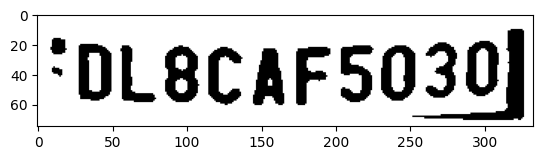

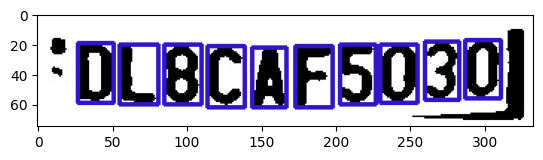

In [117]:
# Let's see the segmented characters
char = segment_characters(plate)

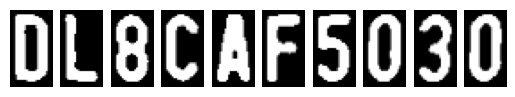

In [118]:
for i in range(10):
    plt.subplot(1, 10, i+1)
    plt.imshow(char[i], cmap='gray')
    plt.axis('off')

## Data Generator

In [20]:
normal_gen = ImageDataGenerator(
    rescale=1./255
)

In [21]:
train_normal = normal_gen.flow_from_directory(
    train_dir,
    target_size=(64,64),
    batch_size=32,
    class_mode='categorical'
)

Found 864 images belonging to 36 classes.


In [22]:
val_normal = normal_gen.flow_from_directory(
    val_dir,
    target_size=(64,64),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)


Found 216 images belonging to 36 classes.


## Augmentation Generator

In [23]:
aug_gen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    zoom_range=0.2,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2
)

In [24]:
train_aug = aug_gen.flow_from_directory(
    train_dir,
    target_size=(64,64),
    batch_size=32,
    class_mode='categorical'
)

Found 864 images belonging to 36 classes.


In [25]:
NUM_CLASSES = len(
    train_normal.class_indices
)

In [26]:
print(NUM_CLASSES)

36


## CNN Model

In [27]:
cnn = Sequential([

    Conv2D(
        32,
        (3,3),
        activation='relu',
        input_shape=(64,64,3)
    ),

    MaxPooling2D(),

    Conv2D(
        64,
        (3,3),
        activation='relu'
    ),

    MaxPooling2D(),

    Conv2D(
        128,
        (3,3),
        activation='relu'
    ),

    MaxPooling2D(),

    Flatten(),

    Dense(
        256,
        activation='relu'
    ),

    Dropout(0.5),

    Dense(
        NUM_CLASSES,
        activation='softmax'
    )
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [28]:
cnn.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [51]:
history_cnn = cnn.fit(
    train_normal,
    validation_data=val_normal,
    epochs=30
)

Epoch 1/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.9803 - loss: 0.0394 - val_accuracy: 0.9676 - val_loss: 0.0739
Epoch 2/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9780 - loss: 0.0473 - val_accuracy: 0.9954 - val_loss: 0.0152
Epoch 3/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9803 - loss: 0.0395 - val_accuracy: 0.9954 - val_loss: 0.0163
Epoch 4/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9884 - loss: 0.0309 - val_accuracy: 0.9954 - val_loss: 0.0155
Epoch 5/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9907 - loss: 0.0244 - val_accuracy: 0.9861 - val_loss: 0.0292
Epoch 6/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 59ms/step - accuracy: 0.9826 - loss: 0.0389 - val_accuracy: 0.9907 - val_loss: 0.0255
Epoch 7/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - accuracy: 0.9838 - loss: 0.0284 - val_accuracy: 0.9954 - val_loss: 0.0126
Epoch 8/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9803 - loss: 0.0430 - val_accuracy: 0.9861 - v

In [52]:
cnn_acc = history_cnn.history['val_accuracy'][-1]

## CNN + Augmentation

In [30]:
cnn_aug = Sequential([

    Conv2D(
        32,
        (3,3),
        activation='relu',
        input_shape=(64,64,3)
    ),

    MaxPooling2D(),

    Conv2D(
        64,
        (3,3),
        activation='relu'
    ),

    MaxPooling2D(),

    Conv2D(
        128,
        (3,3),
        activation='relu'
    ),

    MaxPooling2D(),

    Flatten(),

    Dense(
        256,
        activation='relu'
    ),

    Dropout(0.5),

    Dense(
        NUM_CLASSES,
        activation='softmax'
    )
])

In [31]:
cnn_aug.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [55]:
history_cnn_aug=cnn_aug.fit(
    train_aug,
    validation_data=val_normal,
    epochs=30
)

Epoch 1/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 85ms/step - accuracy: 0.8623 - loss: 0.4139 - val_accuracy: 0.9676 - val_loss: 0.0656
Epoch 2/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 65ms/step - accuracy: 0.8681 - loss: 0.3740 - val_accuracy: 0.9815 - val_loss: 0.0539
Epoch 3/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 69ms/step - accuracy: 0.8785 - loss: 0.3574 - val_accuracy: 0.9630 - val_loss: 0.0614
Epoch 4/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 67ms/step - accuracy: 0.8484 - loss: 0.3993 - val_accuracy: 0.9676 - val_loss: 0.0569
Epoch 5/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 66ms/step - accuracy: 0.8738 - loss: 0.3343 - val_accuracy: 0.9769 - val_loss: 0.0640
Epoch 6/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 69ms/step - accuracy: 0.8715 - loss: 0.3982 - val_accuracy: 0.9722 - val_loss: 0.0502
Epoch 7/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 103ms/step - accuracy: 0.8715 - loss: 0.3611 - val_accuracy: 0.9815 - val_loss: 0.0435
Epoch 8/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 69ms/step - accuracy: 0.8773 - loss: 0.3839 - val_accuracy: 0.9676 - 

In [57]:
cnn_aug_acc = history_cnn_aug.history['val_accuracy'][-1]

## VGG16

In [33]:
vgg_base = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(64,64,3)
)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [34]:
vgg_base.trainable = False


In [35]:
vgg = Sequential([
    vgg_base,

    Flatten(),

    Dense(
        256,
        activation='relu'
    ),

    Dropout(0.5),

    Dense(
        NUM_CLASSES,
        activation='softmax'
    )
])

In [36]:
vgg.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [58]:
history_vgg=vgg.fit(
    train_normal,
    validation_data=val_normal,
    epochs=30
)

Epoch 1/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.9861 - loss: 0.0372 - val_accuracy: 1.0000 - val_loss: 0.0133
Epoch 2/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 0.9919 - loss: 0.0268 - val_accuracy: 1.0000 - val_loss: 0.0127
Epoch 3/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.9907 - loss: 0.0239 - val_accuracy: 0.9907 - val_loss: 0.0177
Epoch 4/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.9884 - loss: 0.0291 - val_accuracy: 0.9907 - val_loss: 0.0173
Epoch 5/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 0.9861 - loss: 0.0323 - val_accuracy: 0.9907 - val_loss: 0.0157
Epoch 6/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 43ms/step - accuracy: 0.9931 - loss: 0.0246 - val_accuracy: 1.0000 - val_loss: 0.0149
Epoch 7/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.9907 - loss: 0.0284 - val_accuracy: 1.0000 - val_loss: 0.0140
Epoch 8/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.9942 - loss: 0.0194 - val_accuracy: 0.9907 - v

In [59]:
vgg_acc = history_vgg.history['val_accuracy'][-1]

## VGG16 + Augmentation

In [38]:
vgg_aug = Sequential([
    vgg_base,

    Flatten(),

    Dense(
        256,
        activation='relu'
    ),

    Dropout(0.5),

    Dense(
        NUM_CLASSES,
        activation='softmax'
    )
])

In [39]:
vgg_aug.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [60]:
history_vgg_aug=vgg_aug.fit(
    train_aug,
    validation_data=val_normal,
    epochs=30
)

Epoch 1/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 75ms/step - accuracy: 0.9155 - loss: 0.2676 - val_accuracy: 0.9954 - val_loss: 0.0437
Epoch 2/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 80ms/step - accuracy: 0.9306 - loss: 0.2255 - val_accuracy: 0.9907 - val_loss: 0.0443
Epoch 3/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 97ms/step - accuracy: 0.8981 - loss: 0.2928 - val_accuracy: 0.9907 - val_loss: 0.0603
Epoch 4/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 86ms/step - accuracy: 0.9074 - loss: 0.2744 - val_accuracy: 0.9907 - val_loss: 0.0415
Epoch 5/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 79ms/step - accuracy: 0.9144 - loss: 0.2565 - val_accuracy: 0.9907 - val_loss: 0.0394
Epoch 6/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 71ms/step - accuracy: 0.9155 - loss: 0.2542 - val_accuracy: 0.9954 - val_loss: 0.0374
Epoch 7/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 85ms/step - accuracy: 0.9363 - loss: 0.2149 - val_accuracy: 0.9769 - val_loss: 0.0531
Epoch 8/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 69ms/step - accuracy: 0.9259 - loss: 0.2317 - val_accuracy: 0.9907 - v

In [61]:
vgg_aug_acc = history_vgg_aug.history['val_accuracy'][-1]

## ResNet50

In [41]:
res_base = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(64,64,3)
)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [42]:
res_base.trainable = False

In [43]:
resnet = Sequential([

    res_base,

    GlobalAveragePooling2D(),

    Dense(
        256,
        activation='relu'
    ),

    Dropout(0.5),

    Dense(
        NUM_CLASSES,
        activation='softmax'
    )
])

In [44]:
resnet.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [62]:
history_resnet=resnet.fit(
    train_normal,
    validation_data=val_normal,
    epochs=30
)

Epoch 1/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.9618 - loss: 0.1957 - val_accuracy: 0.9676 - val_loss: 0.1618
Epoch 2/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.9502 - loss: 0.1824 - val_accuracy: 0.9676 - val_loss: 0.1536
Epoch 3/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.9549 - loss: 0.1906 - val_accuracy: 0.9630 - val_loss: 0.1475
Epoch 4/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 55ms/step - accuracy: 0.9630 - loss: 0.1644 - val_accuracy: 0.9537 - val_loss: 0.1574
Epoch 5/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 0.9641 - loss: 0.1693 - val_accuracy: 0.9676 - val_loss: 0.1432
Epoch 6/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.9699 - loss: 0.1506 - val_accuracy: 0.9722 - val_loss: 0.1465
Epoch 7/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.9583 - loss: 0.1521 - val_accuracy: 0.9583 - val_loss: 0.1520
Epoch 8/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - accuracy: 0.9606 - loss: 0.1549 - val_accuracy: 0.9676 - v

In [63]:
resnet_acc = history_resnet.history['val_accuracy'][-1]

## ResNet50 + Augmentation

In [46]:
resnet_aug = Sequential([

    res_base,

    GlobalAveragePooling2D(),

    Dense(
        256,
        activation='relu'
    ),

    Dropout(0.5),

    Dense(
        NUM_CLASSES,
        activation='softmax'
    )
])

In [47]:
resnet_aug.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [64]:
history_resnet_aug=resnet_aug.fit(
    train_aug,
    validation_data=val_normal,
    epochs=30
)

Epoch 1/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step - accuracy: 0.5116 - loss: 1.5145 - val_accuracy: 0.8194 - val_loss: 0.6520
Epoch 2/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 86ms/step - accuracy: 0.5683 - loss: 1.3998 - val_accuracy: 0.8333 - val_loss: 0.6409
Epoch 3/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 76ms/step - accuracy: 0.5590 - loss: 1.3916 - val_accuracy: 0.8056 - val_loss: 0.6489
Epoch 4/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 4s 138ms/step - accuracy: 0.5440 - loss: 1.4489 - val_accuracy: 0.8380 - val_loss: 0.6204
Epoch 5/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 101ms/step - accuracy: 0.5486 - loss: 1.4289 - val_accuracy: 0.8287 - val_loss: 0.6232
Epoch 6/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 75ms/step - accuracy: 0.5544 - loss: 1.4416 - val_accuracy: 0.8519 - val_loss: 0.6101
Epoch 7/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 74ms/step - accuracy: 0.5637 - loss: 1.3948 - val_accuracy: 0.8287 - val_loss: 0.6234
Epoch 8/30
27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 99ms/step - accuracy: 0.5833 - loss: 1.3706 - val_accuracy: 0.8287 -

In [65]:
resnet_aug_acc = history_resnet_aug.history['val_accuracy'][-1]

## Compare Models

In [69]:
results = pd.DataFrame({
    'Model': [
        'CNN',
        'CNN + Augmentation',
        'VGG16',
        'VGG16 + Augmentation',
        'ResNet50',
        'ResNet50 + Augmentation'
    ],
    'Accuracy': [
        cnn_acc,
        cnn_aug_acc,
        vgg_acc,
        vgg_aug_acc,
        resnet_acc,
        resnet_aug_acc
    ]
})

In [71]:
results

,Model,Accuracy
0,CNN,0.990741
1,CNN + Augmentation,0.962963
2,VGG16,0.990741
3,VGG16 + Augmentation,1.000000
4,ResNet50,0.967593
5,ResNet50 + Augmentation,0.870370


## Select Best Model

In [72]:
best_row = results.loc[
    results['Accuracy'].idxmax()
]

In [73]:
best_model_name = best_row['Model']

In [74]:
print(best_model_name)

VGG16 + Augmentation


In [86]:
models = {
    "CNN": cnn,
    "CNN + Augmentation": cnn_aug,
    "VGG16": vgg,
    "VGG16 + Augmentation": vgg_aug,
    "ResNet50": resnet,
    "ResNet50 + Augmentation": resnet_aug
}

In [87]:
best_model = models[best_model_name]

## Save Best Model

In [89]:
best_model.save("best_model.keras")

In [90]:
import pickle

with open("best_model.pkl", "wb") as f:
    pickle.dump(best_model, f)

## Testing the model with sample image

Saving product.jpeg to product.jpeg


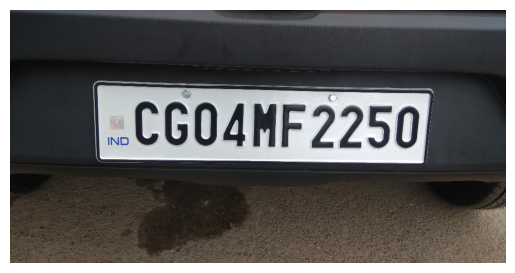

In [125]:
def find_plate(img):

    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

    # try strict detection first, then relax if nothing is found
    for n in [7, 5, 3]:
        plates = plate_cascade.detectMultiScale(
            gray,
            scaleFactor=1.2,
            minNeighbors=n
        )
        if len(plates) > 0:
            break

    if len(plates) == 0:
        return None, None

    # keep only the biggest detection
    x, y, w, h = max(plates, key=lambda p: p[2] * p[3])

    plate = img[y:y+h, x:x+w].copy()      # copy, so the green box is not drawn on the crop

    detected = img.copy()
    cv2.rectangle(detected, (x, y), (x+w, y+h), (0, 255, 0), 3)

    return detected, plate

In [126]:
characters = "0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ"   # same order as the class_0 ... class_Z folders

def read_characters(char_list, model):

    batch = []

    for ch in char_list:
        ch = cv2.resize(ch.astype("float32"), (64, 64), interpolation=cv2.INTER_NEAREST)
        ch = np.stack([ch, ch, ch], axis=-1) / 255.0      # 3 channels + same /255 as training
        batch.append(ch)

    pred = model.predict(np.array(batch), verbose=0)

    return "".join(characters[i] for i in pred.argmax(axis=1))

In [127]:
def recognize_plate(img, model):

    detected, plate = find_plate(img)

    if plate is None:
        print("No number plate found")
        return None

    char_list = segment_characters(plate)

    if len(char_list) == 0:
        print("Plate found, but characters could not be separated")
        return None

    text = read_characters(char_list, model)

    plt.figure(figsize=(12, 6))
    plt.imshow(detected)
    plt.title("Plate number: " + text, fontsize=18)
    plt.axis("off")
    plt.show()

    return text

Saving mumbai-india-april-08-2022-600nw-2144472845.webp to mumbai-india-april-08-2022-600nw-2144472845.webp


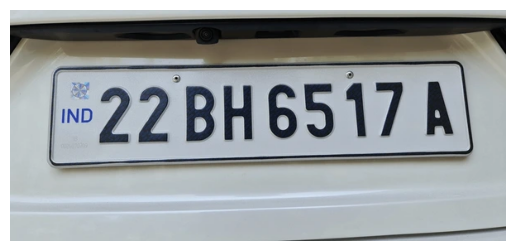

In [155]:
from google.colab import files

uploaded = files.upload()
path = list(uploaded.keys())[0]

img = cv2.imread(path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# shrink very large photos so the plate finder works better
if img.shape[1] > 1000:
    scale = 1000 / img.shape[1]
    img = cv2.resize(img, None, fx=scale, fy=scale)

plt.imshow(img)
plt.axis("off")
plt.show()

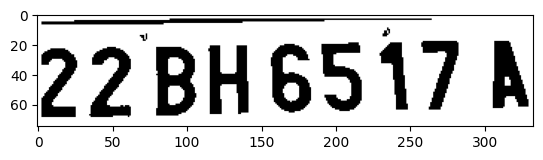

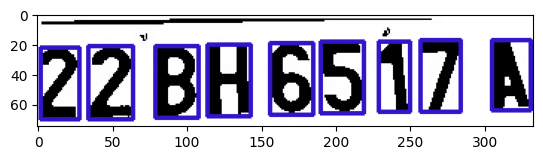

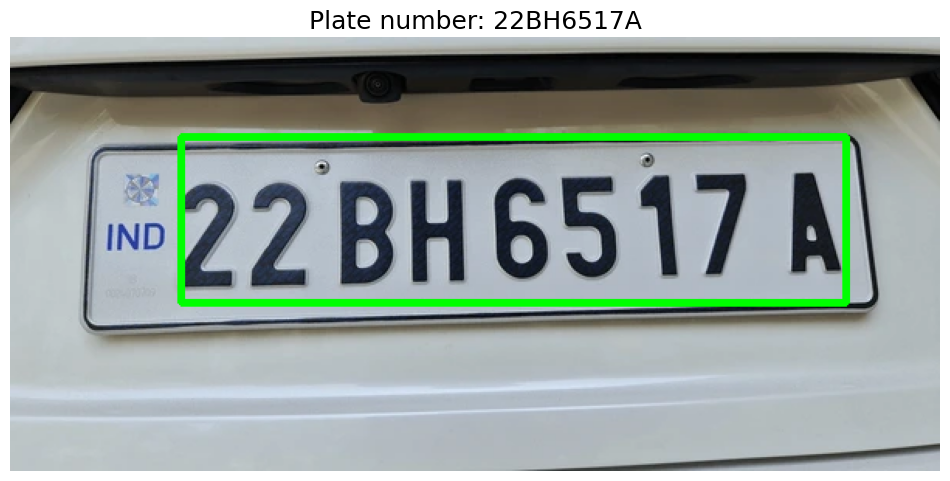

Plate number: 22BH6517A


In [156]:
plate_text = recognize_plate(img, best_model)
print("Plate number:", plate_text)